# 3 · Guía de trabajo en equipo — Boxplots, rango intercuartílico y outliers

> **¿Dónde estamos en el flujo del EDA?**
> Seguimos en el paso **05 – Explorar y analizar**, pero ahora con foco en un problema de calidad que quedó pendiente en el paso **04**: los **valores atípicos (outliers)**.
> Teoría relacionada: láminas *"Box-plots (gráficos de caja)"*, *"Ejemplo con valores e interpretación"* y *"Valores atípicos"*.

> **Pregunta guía del análisis (la misma de los notebooks 0 y 1):**
> ¿Qué características de las células parecen diferenciar un tumor **maligno** (`target = 0`) de uno **benigno** (`target = 1`)?

> **Cómo trabajar**
> 1. Hagan una copia del notebook (*Archivo → Guardar una copia en Drive*) y suban `sample_dataset.csv` al panel **Archivos** (ícono de carpeta, a la izquierda).
> 2. Ejecuten las celdas **en orden** (Shift + Enter).
> 3. Lean los cuadros 📘, completen las celdas 🧩 (reemplazar cada `COMPLETAR`) y respondan en las celdas ✍️.
>    Las celdas 🧩 **dan error hasta que reemplacen `COMPLETAR`**: es esperable, no es un problema del notebook.
> 4. Al final, armen la sección 🎤: **cada equipo va a explicar su notebook al resto del curso en 5 minutos.**
>
> | Ícono | Significa |
> |---|---|
> | 📘 | Concepto (relacionado con la teoría vista) |
> | 💻 | Código listo para ejecutar y observar |
> | 🧩 | Código para completar (reemplazar `COMPLETAR`) |
> | ✍️ | Pregunta para responder en equipo |
> | ⭐ | Extra, solo si les sobra tiempo |
> | 🎤 | Lo que van a presentar al resto |

## 0) Preparación

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# Cada notebook es independiente: hay que volver a importar librerías y cargar los datos.
# Si aparece FileNotFoundError: el CSV no está subido en el panel "Archivos" de ESTE notebook.
df = pd.read_csv("sample_dataset.csv")
df.shape   # esperamos (569, 31)

(569, 31)

## 1) Anatomía de un boxplot

📘 **Concepto.** El boxplot resume una variable numérica en **5 números** + los atípicos:

| Elemento | Qué es |
|---|---|
| Línea del medio de la caja | **Mediana (Q2)**: el 50% de los datos está por debajo |
| Borde inferior de la caja | **Q1** (percentil 25) |
| Borde superior de la caja | **Q3** (percentil 75) |
| Alto de la caja | **Rango intercuartílico: RIC = Q3 − Q1** → ahí está el 50% central de los datos |
| Límite inferior | **Li = Q1 − 1,5 · RIC** |
| Límite superior | **Ls = Q3 + 1,5 · RIC** |
| Bigotes | Llegan hasta el valor más extremo que **no** es atípico (dentro de [Li, Ls]) |
| Puntos sueltos | **Outliers**: valores menores que Li o mayores que Ls |

**Cómo se interpreta:** caja más alta → más variabilidad; bigotes desiguales o mediana corrida → asimetría; puntos fuera de los bigotes → valores atípicos.

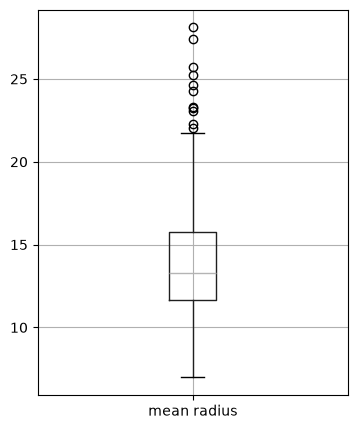

In [15]:
df[["mean radius"]].boxplot(figsize=(4, 5))
plt.show()

✍️ **Preguntas** (respondan **mirando solo el gráfico**, sin calcular):
1. ¿Aproximadamente cuánto valen Q1, la mediana y Q3?
2. ¿Hay outliers? ¿Están por arriba, por abajo o en ambos lados?
3. ¿La distribución parece simétrica? ¿Qué pista del gráfico lo indica?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 2) Calculemos los límites "a mano"

🧩 **Completen** los dos `COMPLETAR` usando las fórmulas de la tabla anterior.
`quantile(p)` devuelve el valor por debajo del cual queda la proporción `p` de los datos (0.25 = Q1).

In [ ]:
s = df["mean radius"].dropna()   # trabajamos sin los faltantes

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
ric = q3 - q1
li = q1 - 1.5 * ric
ls = q3 + 1.5 * ric

print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | RIC = {ric:.2f}")
print(f"Límite inferior = {li:.2f} | Límite superior = {ls:.2f}")

# Una "máscara" es una Serie de True/False: True donde se cumple la condición
outliers = s[(s < li) | (s > ls)]     # | significa "o"
print("Cantidad de outliers:", len(outliers))
print("Valores:", sorted(outliers.round(2).tolist()))

Q1 = 11.67 | Q3 = 15.75 | RIC = 4.07
Límite inferior = -52.45 | Límite superior = 21.85
Cantidad de outliers: 11
Valores: [22.01, 22.27, 23.09, 23.27, 23.29, 24.25, 24.63, 25.22, 25.73, 27.42, 28.11]


✍️ **Pregunta:** ¿Coinciden los valores calculados con lo que estimaron en el gráfico? ¿Por qué el límite inferior no tiene outliers? (pista: comparen Li con el mínimo de la variable).

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 3) Boxplot y histograma: dos miradas de lo mismo

💻 Ponemos uno al lado del otro. El boxplot **resume**, el histograma muestra la **forma completa**.

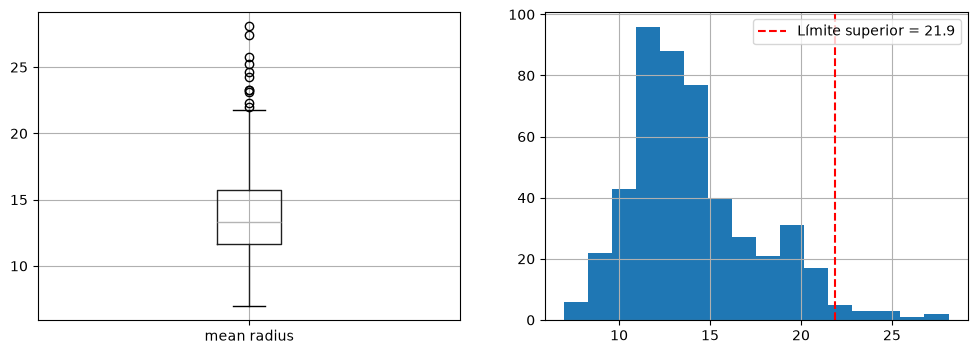

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
df[["mean radius"]].boxplot(ax=ax1)
df["mean radius"].hist(bins="rice", ax=ax2)
ax2.axvline(ls, color="red", linestyle="--", label=f"Límite superior = {ls:.1f}")
ax2.legend()
plt.show()

✍️ **Pregunta:** ¿Dónde se ven los outliers en el histograma? ¿Qué relación hay entre la **cola** del histograma y los **puntos sueltos** del boxplot?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 4) Comparar varias variables: el problema de las escalas

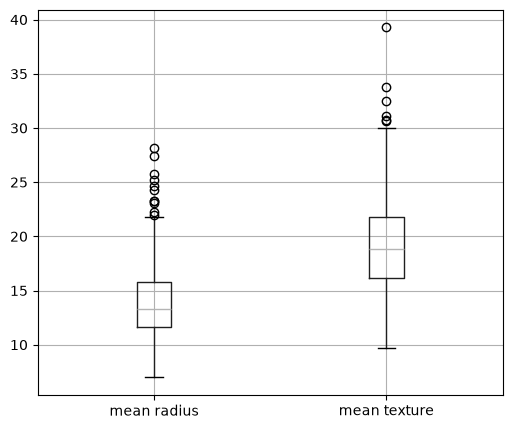

In [18]:
# Dos variables en el mismo gráfico
df[["mean radius", "mean texture"]].boxplot(figsize=(6, 5))
plt.show()

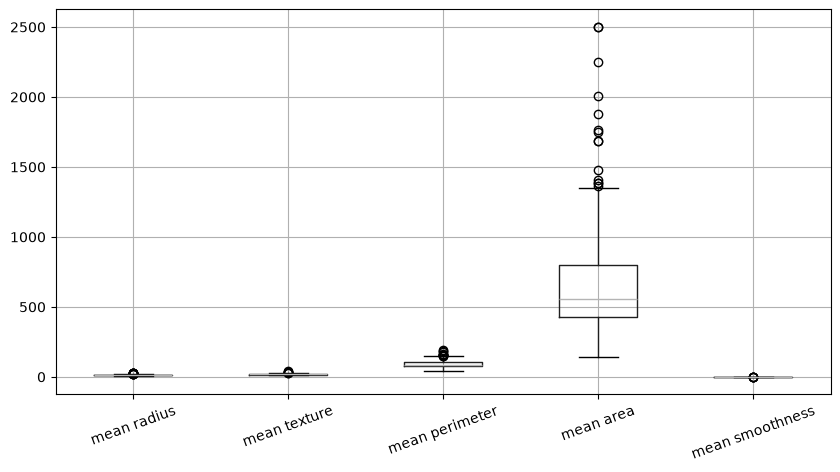

In [19]:
# Las primeras 5 variables
df.iloc[:, 0:5].boxplot(figsize=(10, 5), rot=20)   # rot = rotación de los nombres del eje X
plt.show()

✍️ **Pregunta:** En el gráfico de 5 variables, ¿se puede analizar la caja de `mean smoothness`? ¿Por qué pasa esto?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

📘 **Concepto: estandarización (z-score).** Para comparar variables con escalas distintas, las llevamos a una escala común:

$$z = \frac{x - \text{media}}{\text{desvío estándar}}$$

Después de estandarizar, cada variable tiene media 0 y desvío 1: un valor z = 2 significa "2 desvíos por encima del promedio". **No cambia la forma** de la distribución, solo la escala. Muchos modelos que van a ver más adelante necesitan este paso.

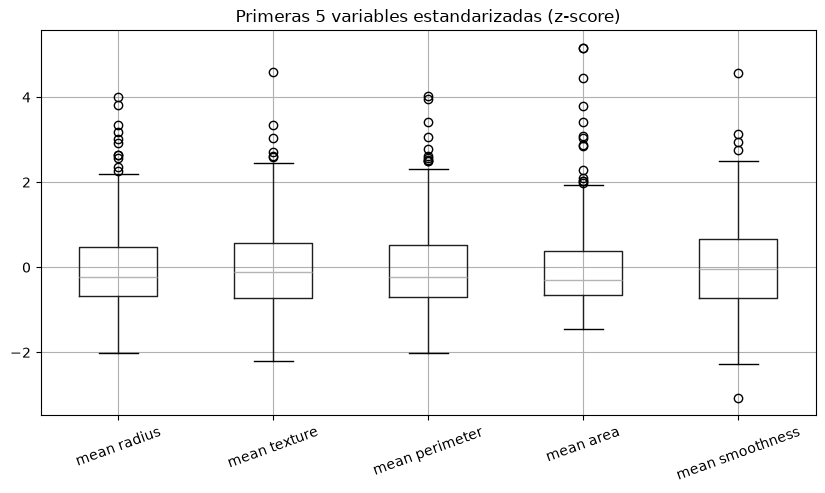

In [20]:
cols = df.columns[0:5]
df_z = (df[cols] - df[cols].mean()) / df[cols].std()

df_z.boxplot(figsize=(10, 5), rot=20)
plt.title("Primeras 5 variables estandarizadas (z-score)")
plt.show()

✍️ **Pregunta:** Ahora que están en la misma escala, ¿qué variable tiene **más outliers**? ¿Alguna tiene outliers **por abajo**?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 5) ¿Cuántos outliers tiene cada variable?

💻 Convertimos el cálculo de la sección 2 en una **función** y la aplicamos a todas las columnas numéricas.

In [21]:
def contar_outliers(serie):
    """Cuenta los valores fuera de [Q1 - 1.5*RIC, Q3 + 1.5*RIC]."""
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    ric = q3 - q1
    return int(((s < q1 - 1.5 * ric) | (s > q3 + 1.5 * ric)).sum())

columnas = df.select_dtypes("number").columns.drop("target")   # todas las numéricas menos target
resumen = pd.Series({col: contar_outliers(df[col]) for col in columnas}).sort_values(ascending=False)
resumen

radius error               32
smoothness error           26
perimeter error            25
fractal dimension error    24
symmetry error             23
compactness error          23
worst fractal dimension    22
worst area                 21
worst symmetry             18
concave points error       16
mean compactness           16
mean concavity             16
texture error              16
concavity error            15
worst radius               15
worst compactness          15
mean area                  14
mean symmetry              13
mean fractal dimension     12
mean radius                11
worst perimeter            11
worst concavity            10
mean perimeter             10
mean concave points         7
mean texture                6
mean smoothness             5
worst texture               5
worst smoothness            5
worst concave points        0
dtype: int64

✍️ **Pregunta:** ¿Cuáles son las 3 variables con más outliers? ¿Qué tienen en común (piensen en el tipo de medida: `mean`, `error`, `worst`)?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 6) ¿Eliminar o mantener? Miremos a quién corresponden los outliers

📘 **Concepto.** Un outlier **no es automáticamente un error**. Puede ser:
- un **error de carga o medición** → se corrige o se elimina;
- un **valor real pero extremo** → se mantiene, y muchas veces es **lo más interesante** del análisis.

La decisión depende del **contexto**. Recuerden también que los outliers pueden **distorsionar** medidas como la media o la correlación (lámina *"Valores atípicos"*).

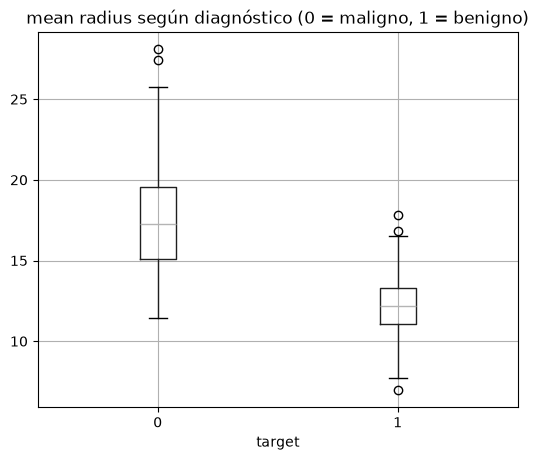

target
0    11
Name: count, dtype: int64

In [22]:
# Boxplot de mean radius separado por diagnóstico
df.boxplot(column="mean radius", by="target", figsize=(6, 5))
plt.suptitle("")   # quita el título automático de pandas
plt.title("mean radius según diagnóstico (0 = maligno, 1 = benigno)")
plt.show()

# ¿Qué diagnóstico tienen los outliers que encontramos en la sección 2?
df.loc[outliers.index, "target"].value_counts()

🧩 **Tu turno.** Repitan el análisis con otra variable: `"worst area"`, `"mean concave points"` o `"mean texture"`.

In [23]:
def outliers_por_diagnostico(var):
    df.boxplot(column=var, by="target", figsize=(6, 5))
    plt.suptitle(""); plt.title(f"{var} según diagnóstico (0 = maligno, 1 = benigno)")
    plt.show()
    s = df[var].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    ric = q3 - q1
    idx = s[(s < q1 - 1.5 * ric) | (s > q3 + 1.5 * ric)].index
    print(f"{len(idx)} outliers en {var}. Diagnóstico de esos outliers:")
    print(df.loc[idx, "target"].value_counts().rename({0: "maligno", 1: "benigno"}))

outliers_por_diagnostico(COMPLETAR)

NameError: name 'COMPLETAR' is not defined

✍️ **Preguntas**
1. ¿A qué diagnóstico corresponden casi todos los outliers de `mean radius`? ¿Y los de la variable que eligieron?
2. En este contexto, ¿eliminarían esos outliers? Justifiquen pensando en qué representan (¿error de medición o tumores realmente grandes?).

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_